# 05 · After a neutron-star merger, for how many days can Lazuli's IFS keep getting a useful kilonova spectrum at 40 Mpc and 200 Mpc?

AT2017gfo faded by ~5 mag in the optical within ten days while its emission shifted into the near-infrared, where ground-based spectroscopy is hardest. The late-time spectra are where the lanthanide/actinide features live, so the useful lifetime of a space-based IFS follow-up is set by how long the red/NIR S/N holds up. Here we ask that for a GW170817-like event (40 Mpc) and for one at the O4/O5 BNS horizon (~200 Mpc).

**Instrument / code:** Lazuli IFS, `slicersim` (v1.3.4): `LazuliKilonova` (POSSIS Bulla 2023 grid), `change_detector`, `get_band_snr`, `get_spectrum`.

## Prompt to try in Jupyter AI

> Using the `slicersim` package (Lazuli IFS simulator), make a `slicersim.LazuliKilonova(model="bulla23", redshift=z, theta=30, magabs=-15.8, band="sdssr")` for luminosity distances of 40 and 200 Mpc (convert to redshift with astropy Planck18).
> Fix a one-hour read-out with `change_detector(nmd=(53, 8, 0), nramps=3)`, then step `change_properties(phase=t)` from 0.5 to 30 days after merger.
> At each phase record `get_band_snr([6000, 9000], frame="obs")` (optical) and `get_band_snr([10000, 16000], frame="obs")` (NIR), both per resolution element.
> Plot S/N vs days since merger (log-log) for both distances and both bands, with a dashed line at S/N = 5, next to example noisy spectra at 1, 3 and 7 days for 200 Mpc.
> Print the last day each curve stays above S/N = 5.
> Tell me how the model is normalised (peak absolute magnitude, which band), what viewing angle is assumed, and the phase range covered by the POSSIS grid.

## Setup

The kilonova is the POSSIS Bulla (2023) model seen at $\theta = 30^\circ$, normalised to a peak $M_r = -15.8$ (the slicersim default, close to AT2017gfo). Distances are converted to redshift with Planck18.

In [1]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('gks')
import astropy.units as u
from astropy.cosmology import Planck18, z_at_value
import slicersim
from slicersim.scene.sources.kilonova import get_kilonova_model, bulla23_url

print('slicersim', slicersim.__version__)
THUMB = Path('../thumbs/05_kilonova_followup.png')
ONE_HOUR = dict(nmd=(53, 8, 0), nramps=3)
BANDS = {'optical 0.6-0.9 µm': [6000, 9000], 'NIR 1.0-1.6 µm': [10000, 16000]}
DIST = [40, 200]   # Mpc
ZS = {d: float(z_at_value(Planck18.luminosity_distance, d * u.Mpc)) for d in DIST}
print('redshifts:', {d: round(z, 4) for d, z in ZS.items()})

m = get_kilonova_model(bulla23_url)
print(f"POSSIS bulla23 grid: phase {m.source.minphase():.2f}-{m.source.maxphase():.1f} d (flux held constant outside)")

slicersim 1.3.4
redshifts: {40: 0.009, 200: 0.0437}
POSSIS bulla23 grid: phase 0.21-30.8 d (flux held constant outside)


## S/N in one hour versus days since merger

One target per distance; we only change the phase, so each step is a fast spectrum evaluation (no read-out search).

In [2]:
PHASES = np.round(np.geomspace(0.5, 30, 21), 2)
snr = {}
t0 = time.time()
kn = {}
for d in DIST:
    kn[d] = slicersim.LazuliKilonova(model='bulla23', redshift=ZS[d], theta=30, magabs=-15.8, band='sdssr', phase=1)
    kn[d].change_detector(**ONE_HOUR)
    for name, rng in BANDS.items():
        s = []
        for ph in PHASES:
            kn[d].change_properties(phase=ph)
            s.append(kn[d].get_band_snr(rng, frame='obs', per_resolution=True))
        snr[d, name] = np.array(s)
print(f"exposure {kn[40].get_exposure_time():.0f} s; grid done in {time.time()-t0:.0f} s\n")
print('days  ' + '  '.join(f'{d}Mpc/{n.split()[0]:>7s}' for d in DIST for n in BANDS))
for i, ph in enumerate(PHASES):
    print(f'{ph:5.2f} ' + '  '.join(f'{snr[d, n][i]:14.1f}' for d in DIST for n in BANDS))

exposure 3600 s; grid done in 77 s

days  40Mpc/optical  40Mpc/    NIR  200Mpc/optical  200Mpc/    NIR
 0.50          605.5           675.3           116.5           132.6
 0.61          664.6           737.1           129.7           139.4
 0.75          637.3           762.6           125.5           141.7
 0.92          599.4           775.5           114.6           152.2
 1.13          601.0           784.1           117.0           154.5
 1.39          589.3           805.4           111.0           152.7
 1.71          597.4           833.7           109.7           160.2
 2.10          593.2           880.7           114.1           168.7
 2.57          576.3           905.3           112.0           173.1
 3.16          548.5           920.0           104.2           178.1
 3.87          486.2           880.1            90.9           169.2
 4.75          409.2           813.2            75.0           157.3
 5.83          309.2           717.1            54.2           137.3


## How long does each case stay above S/N = 5 per resolution element?

In [3]:
def last_day(s, thr=5.0):
    above = s >= thr
    if above.all():
        return f'> {PHASES[-1]:.0f} d (whole grid)'
    if not above.any():
        return 'never'
    i = np.where(above)[0].max()            # last grid point above threshold
    # log-log interpolation to the crossing
    x = np.interp(np.log10(thr), np.log10([s[i+1], s[i]]), np.log10([PHASES[i+1], PHASES[i]]))
    return f'{10**x:.1f} d'

for d in DIST:
    for n in BANDS:
        print(f'{d:3d} Mpc, {n:18s}: S/N >= 5 until {last_day(snr[d, n])}')

 40 Mpc, optical 0.6-0.9 µm: S/N >= 5 until 16.4 d
 40 Mpc, NIR 1.0-1.6 µm    : S/N >= 5 until 25.2 d
200 Mpc, optical 0.6-0.9 µm: S/N >= 5 until 10.6 d
200 Mpc, NIR 1.0-1.6 µm    : S/N >= 5 until 17.7 d


## Example spectra (200 Mpc, one hour)

In [4]:
np.random.seed(1)
spec = {}
for ph in [1, 3, 7]:
    kn[200].change_properties(phase=ph)
    l, f, v = kn[200].get_spectrum(unit='flambda', incl_error=True)
    _, f0, _ = kn[200].get_spectrum(unit='flambda', incl_error=False)
    spec[ph] = (l, f, f0)

## Hero figure

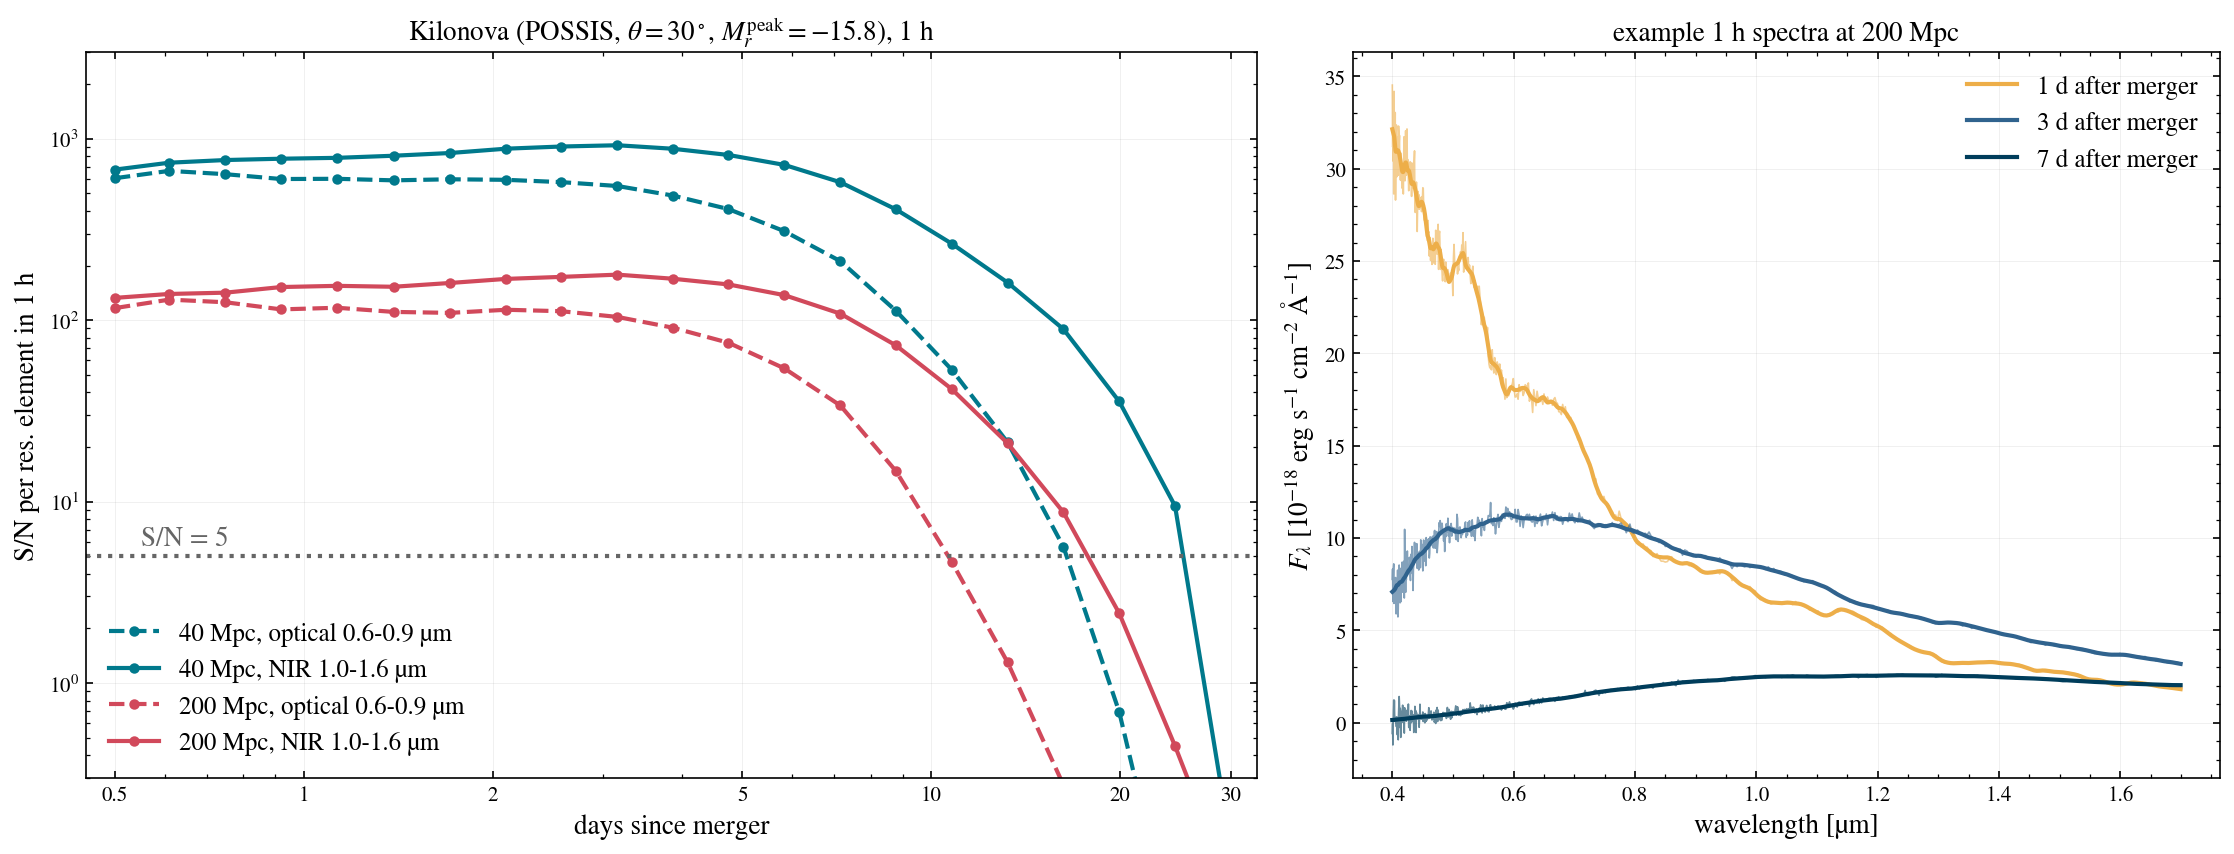

In [5]:
from matplotlib.ticker import FixedLocator, FixedFormatter
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw=dict(width_ratios=[1.35, 1]))
cols = {40: '#00798c', 200: '#d1495b'}
ls = {'optical 0.6-0.9 µm': '--', 'NIR 1.0-1.6 µm': '-'}
for d in DIST:
    for n in BANDS:
        ax.loglog(PHASES, snr[d, n], ls=ls[n], color=cols[d], marker='o', ms=4, label=f'{d} Mpc, {n}')
ax.axhline(5, color='0.4', ls=':')
ax.text(0.55, 5.8, 'S/N = 5', color='0.4', fontsize=13)
ticks = [0.5, 1, 2, 5, 10, 20, 30]
ax.xaxis.set_major_locator(FixedLocator(ticks)); ax.xaxis.set_major_formatter(FixedFormatter([str(t) for t in ticks]))
ax.set(xlabel='days since merger', ylabel='S/N per res. element in 1 h', ylim=(0.3, 3e3), xlim=(0.45, 33),
       title=r'Kilonova (POSSIS, $\theta=30^\circ$, $M_r^{\rm peak}=-15.8$), 1 h')
ax.legend(loc='lower left', fontsize=12)

for ph, c in zip(spec, ['#edae49', '#30638e', '#003d5b']):
    l, f, f0 = spec[ph]
    ax2.plot(l / 1e4, f * 1e18, color=c, lw=0.8, alpha=0.6)
    ax2.plot(l / 1e4, f0 * 1e18, color=c, lw=2, label=f'{ph} d after merger')
ax2.set(xlabel=r'wavelength [µm]', ylabel=r'$F_\lambda$ [$10^{-18}$ erg s$^{-1}$ cm$^{-2}$ Å$^{-1}$]',
        title='example 1 h spectra at 200 Mpc')
ax2.legend(fontsize=12)
fig.tight_layout()
fig.savefig(THUMB, dpi=150)
plt.show()

## Answer

For an AT2017gfo-like kilonova (POSSIS, θ = 30°, peak $M_r = -15.8$) a one-hour IFS visit keeps S/N ≥ 5 per resolution element in the NIR (1.0–1.6 µm) until **~25 days** after merger at 40 Mpc and **~18 days** at 200 Mpc. The optical (0.6–0.9 µm) dies earlier: ~16 d at 40 Mpc and ~11 d at 200 Mpc. Past about a week, the NIR is what keeps the follow-up going.

## Caveats & next steps

- **One model, one angle:** a single POSSIS (Bulla 2023) model at $\theta = 30^\circ$, scaled to a peak $M_r = -15.8$. In slicersim every viewing angle is normalised to the *same* peak magnitude, so changing `theta` changes the colour evolution but not the intrinsic angle-dependent brightness. Real kilonovae span a wide range of ejecta masses and peak luminosities.
- **Grid edge:** the POSSIS grid stops at ~31 days; beyond that the flux is held constant, so do not extend the phase axis past it.
- **Idealised point source:** no host-galaxy light (GW170817's host was a bright early-type galaxy at 10″), no Galactic extinction, no response-time or slew constraints, and the S/N is a band-averaged mean per resolution element (useful for continuum shape; individual features need more).
- **Ideas:** (1) scan `theta` = 0, 45, 90 and see how much the NIR lifetime changes; (2) instead of a fixed hour, use `setup_to_snr(5, lbda_range=[10000, 16000], frame='obs')` to get the exposure time needed each night and add up the total follow-up campaign cost; (3) put the kilonova on a host with the `advanced_host_galaxy` tutorial scene.